# Supplementary Fig. 11: Xenium non-small-cell lung cancer

Segmentation footprints and neighbourhoods against a membrane-stain reference.
Segger, Proseg and Baysor are compared with a Cellpose segmentation of the NaK-ATPase membrane and DAPI image of the Xenium NSCLC section of Fig. 4, restricted to epithelial/cancer cells.

| | |
|---|---|
| Data | Xenium NSCLC section, Cellpose membrane reference and image, segmentations of all methods, CellTypist compartment model |
| Compute | CPU, about 200 GB RAM. Cellpose cell types (CUDA GPU, RAPIDS) and transcript-contact neighbours are cached in `results/supp_figure_11`. |
| Output | `results/supp_figure_11/panel_{a,b,c,d,e-g,h-i}.{pdf,png}` |

In [1]:
import json
import logging
import subprocess
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices raised on import

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import scanpy as sc
import seaborn as sns

import sg_utils as sg
from sg_utils.pl.plot_morphology import plot_cell_outlines, plot_morphology_image
from sg_utils.tl.footprints import (
    centroid_neighbor_diffs,
    compute_metrics,
    get_bins_with_mst,
    map_labels,
    neighbor_difference,
    point_neighbor_edges,
)

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
ASSETS = Path(sg.pl.__file__).parent / "assets"
plt.style.use(ASSETS / "default.mplstyle")
plt.rcParams["savefig.bbox"] = "tight"
method_palette = json.loads((ASSETS / "palettes.json").read_text())["Method"]

In [2]:
DATA_DIR = Path("../data")
OUT_DIR = Path("../results/supp_figure_11")
RUN_SEGGER = False  # True runs `segger segment` (CUDA GPU); False downloads the published segmentation

## Download the data

The Xenium NSCLC data of Fig. 4; the CellTypist model is only needed to type the Cellpose cells.

In [3]:
path_cell_types = OUT_DIR / "cellpose_cell_types.parquet"
path_transcript_diffs = OUT_DIR / "transcript_neighbor_diffs.parquet"

files = ["xenium", "cellpose", "segmentations"] + ([] if RUN_SEGGER else ["segger"])
files += [] if path_cell_types.exists() else ["celltypist"]
paths = sg.datasets.fetch("xenium_nsclc", DATA_DIR, files=files)
paths

{'xenium': PosixPath('../data/xenium_nsclc/xenium'),
 'cellpose': PosixPath('../data/xenium_nsclc/cellpose'),
 'segger': PosixPath('../data/xenium_nsclc/segger/segger_segmentation.parquet'),
 'segmentations': PosixPath('../data/xenium_nsclc/segmentations.parquet')}

## Run Segger

As in Fig. 4.

In [4]:
segger_dir = DATA_DIR / "xenium_nsclc" / "segger"
segger_dir.mkdir(parents=True, exist_ok=True)
if RUN_SEGGER:
    subprocess.run([
        "segger", "segment", "-i", paths["xenium"], "-o", segger_dir,
        "--prediction-graph-buffer-ratio", "0.1", "--tiling-margin-training", "8", "--tiling-margin-prediction", "8",
    ], check=True)

## Load transcripts and segmentations

All decoded transcripts, with one cell-id column per segmentation; `Segger` holds the kept assignments.

In [5]:
SEGMENTATIONS = ["Segger", "Proseg", "Baysor"]
REFERENCE = "Cellpose"
NAMES = {"Segger": "segger", "Proseg": "Proseg", "Baysor": "Baysor"}
XY = dict(x_column="x", y_column="y")

tx = sg.io.join_assignments(
    sg.io.read_transcripts(paths["xenium"] / "transcripts.parquet", min_qv=0, controls=True, lazy=True),
    sg.io.read_segger(segger_dir / "segger_segmentation.parquet", lazy=True),
    sg.io.read_segmentations(paths["segmentations"], lazy=True),
    how="left",
).with_columns(pl.col("feature_name", *SEGMENTATIONS, REFERENCE).cast(pl.Utf8))
tx.head()

row_index,x,y,feature_name,Segger,Cellpose,Proseg,Baysor
i64,f32,f32,str,str,str,str,str
0,47.734108,108.26403,"""VIM""",null,null,null,null
1,48.848789,109.301132,"""VIM""",null,null,null,null
2,72.893158,206.97113,"""VIM""",null,null,null,null
3,169.894943,50.339771,"""GPX8""",null,null,null,null
4,194.803864,231.869537,"""NFKB1""",null,null,null,null


## Cellpose cell types

Cellpose cells (at least 20 transcripts) are typed into compartments with the CellTypist model of the NSCLC atlas, by majority vote over PhenoGraph clusters.

In [6]:
if not path_cell_types.exists():
    from segger.data.utils import anndata_from_transcripts

    from sg_utils.pp.preprocess_rapids import preprocess_rapids
    from sg_utils.tl.celltypist_utils import annotate_cell_types

    ad_cp = anndata_from_transcripts(tx.select("feature_name", REFERENCE).drop_nulls(REFERENCE), "feature_name", REFERENCE)
    ad_cp.raw = ad_cp.copy()
    preprocess_rapids(ad_cp, filter_min_counts=20, pca_layer="lognorm")
    annotate_cell_types(
        ad_cp, raw_layer="counts", ct_model=str(paths["celltypist"] / "nsclc_celltypist_model.pkl"),
        cluster_col="phenograph_cluster", target_sum=100,
    )
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    pl.DataFrame({
        REFERENCE: np.asarray(ad_cp.obs_names, dtype=str),
        "cellpose_cell_type": ad_cp.obs["celltypist_label"].astype(str).to_numpy(),
    }).write_parquet(path_cell_types)

## Epithelial cells and matches to Cellpose

Cells whose transcripts are more than one third from epithelial/cancer Cellpose cells are kept.
Each cell is rasterized to 2 µm bins (split cells bridged by a minimum spanning tree) and matched to the Cellpose cell holding more than a quarter of its transcripts.

In [7]:
bin_width = 2
tx = (
    tx
    .join(pl.read_parquet(path_cell_types), on=REFERENCE, how="left")
    .with_columns(pl.col("cellpose_cell_type").eq_missing("Epithelial/Cancer").alias("is_epithelial"))
    .with_columns(
        pl.when(pl.col("is_epithelial").mean().over(column).gt(1 / 3)).then(pl.col(column)).otherwise(None)
        for column in SEGMENTATIONS + [REFERENCE]
    )
)
all_bins = {
    column: get_bins_with_mst(tx, column, bin_width=bin_width, **XY)
    for column in SEGMENTATIONS + [REFERENCE]
}
all_mappings = {column: map_labels(tx, column, REFERENCE, 1 / 4) for column in SEGMENTATIONS}

## Transcript-contact neighbours

Cells sharing a transcript pair within 1–7 µm, per segmentation; per matched cell, the neighbours added or dropped relative to its Cellpose cell, in Cellpose ids.
Cached in `OUT_DIR`.

In [8]:
if not path_transcript_diffs.exists():
    radii = [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]
    edges = {column: point_neighbor_edges(tx, column, radii, **XY) for column in SEGMENTATIONS + [REFERENCE]}
    diffs = []
    for column in SEGMENTATIONS:
        for radius in radii:
            method_edges = edges[column].filter(pl.col("radius") == radius).select(["cell", "neighbor"])
            reference_edges = edges[REFERENCE].filter(pl.col("radius") == radius).select(["cell", "neighbor"])
            diff = neighbor_difference(method_edges, reference_edges, all_mappings[column], column, REFERENCE)
            diffs.append(diff.with_columns(pl.lit(column).alias("segmentation"), pl.lit(radius).alias("radius")))
    pl.concat(diffs).write_parquet(path_transcript_diffs)
    del edges

In [9]:
def barplot(data, ax, y, errorbar=("pi", 50)):
    sns.barplot(
        data, x="segmentation", y=y, order=list(NAMES.values()), hue="segmentation", palette=method_palette,
        legend=False, errorbar=errorbar, err_kws=dict(linewidth=0.5, color="k"), capsize=0.3, width=0.6,
        saturation=1, ax=ax,
    )
    ax.set_xticks(ax.get_xticks(), ax.get_xticklabels(), rotation=45, ha="right", va="top", rotation_mode="anchor")
    ax.set_xlabel("")

## Panel a: Cellpose on the membrane stain

Cellpose outlines over the membrane (cyan) and DAPI (red) image; scale bar, 20 µm.

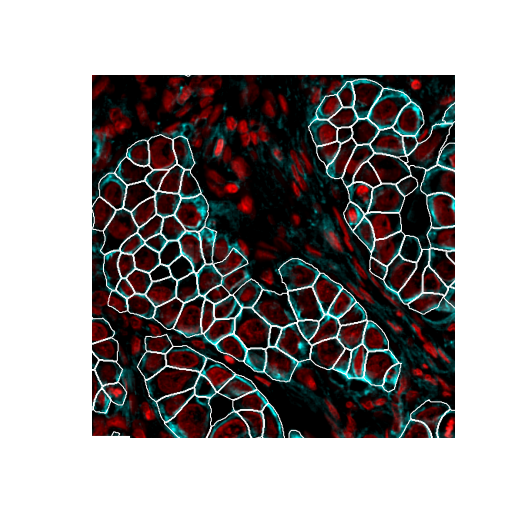

In [10]:
image = np.load(paths["cellpose"] / "segmentation_image.npy")
boundaries = gpd.read_parquet(paths["cellpose"] / "cellpose_mask_polygons.parquet")
boundaries.index = boundaries.index.astype(str)
boundaries = boundaries[boundaries.index.isin(tx[REFERENCE].drop_nulls().unique().to_list())]
xmin, ymin, xmax, ymax = 6685, 11525, 6885, 11725
mpp = 0.2125 * 2

fig, ax = plt.subplots(1, 1, figsize=(2, 2))
plot_morphology_image(image, boundaries, xmin, ymin, xmax, ymax, ax, mpp=mpp)
ax.plot([xmin, xmin + 20], [ymin, ymin], lw=1, c="w")
ax.axis("off")
sg.pl.save_panel(fig, OUT_DIR / "panel_a")

## Panels b–d: method outlines over Cellpose

Each method's cells outlined over the filled Cellpose cells, coloured by the Cellpose cell they match.

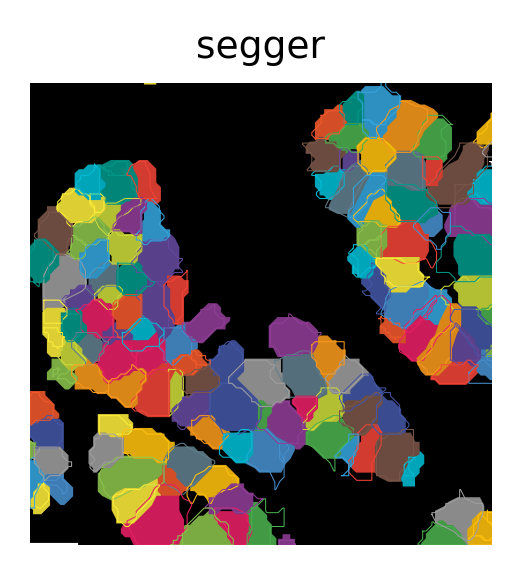

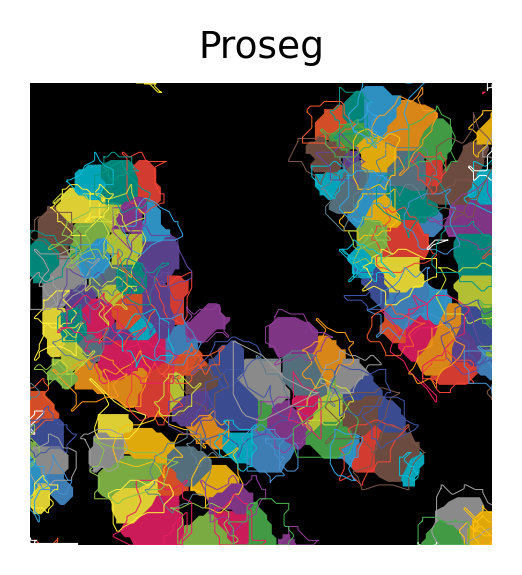

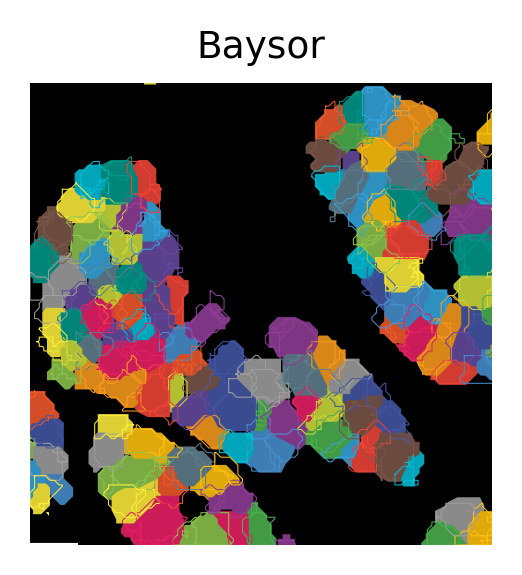

In [11]:
for panel, column in zip("bcd", SEGMENTATIONS):
    fig, ax = plt.subplots(1, 1, figsize=(2, 2))
    plot_cell_outlines(
        all_bins[REFERENCE], all_bins[column], REFERENCE, column, xmin=xmin, xmax=xmax, ymin=ymin, ymax=ymax,
        bin_width=bin_width, mapping=all_mappings[column], linewidth=0.25, alpha=0.875, concave_hull=True, ax=ax,
    )
    ax.plot([xmin, xmin + 20], [ymin, ymin], lw=1, c="w")
    ax.set_title(NAMES[column])
    ax.set_facecolor("k")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines:
        ax.spines[spine].set_visible(False)
    sg.pl.save_panel(fig, OUT_DIR / f"panel_{panel}")

## Panels e–g: footprint overlap

Per matched cell, IoU and area relative to its Cellpose cell; per Cellpose cell, the method cells with more than a quarter of their bins inside it.
Bars, median; error bars, interquartile range.

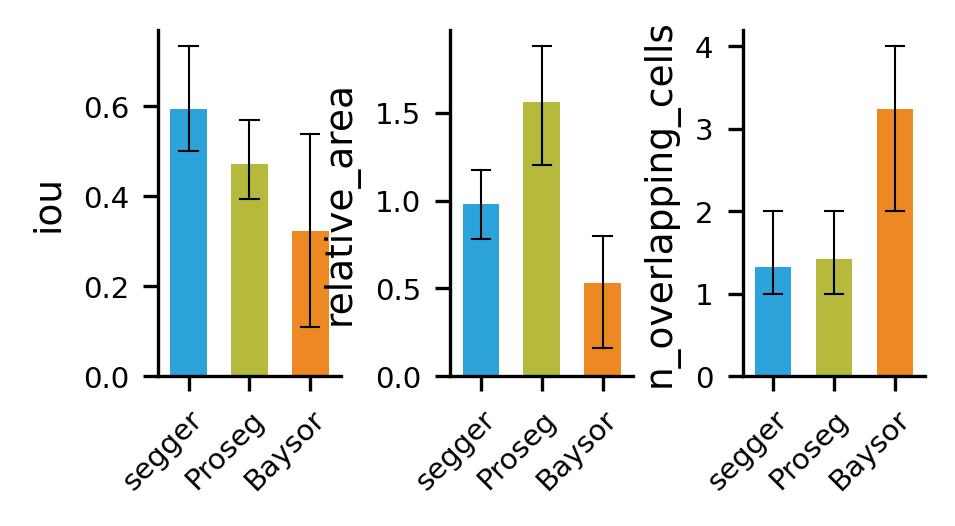

In [12]:
cell_metrics, overlap_metrics = [], []
for column in SEGMENTATIONS:
    cells, overlap = compute_metrics(
        all_bins[column], all_bins[REFERENCE], all_mappings[column], column, REFERENCE, min_overlap_fraction=0.25,
    )
    cell_metrics.append(cells.select(["segmentation", "iou", "relative_area"]))
    overlap_metrics.append(overlap.select(["segmentation", "n_overlapping_cells"]))
cell_metrics = pl.concat(cell_metrics).with_columns(pl.col("segmentation").replace(NAMES))
overlap_metrics = pl.concat(overlap_metrics).with_columns(pl.col("segmentation").replace(NAMES))

fig, axes = plt.subplots(1, 3, figsize=(3.3, 1.5), gridspec_kw=dict(wspace=0.6))
barplot(cell_metrics, axes[0], "iou")
barplot(cell_metrics, axes[1], "relative_area")
barplot(overlap_metrics, axes[2], "n_overlapping_cells")
sg.pl.save_panel(fig, OUT_DIR / "panel_e-g")

## Panels h and i: neighbourhood preservation

Neighbours added plus dropped relative to the matched Cellpose cell, over its Cellpose neighbours: transcript centroids within 20 µm (h) and transcript contacts within 5 µm (i); 100,000 cells per method.

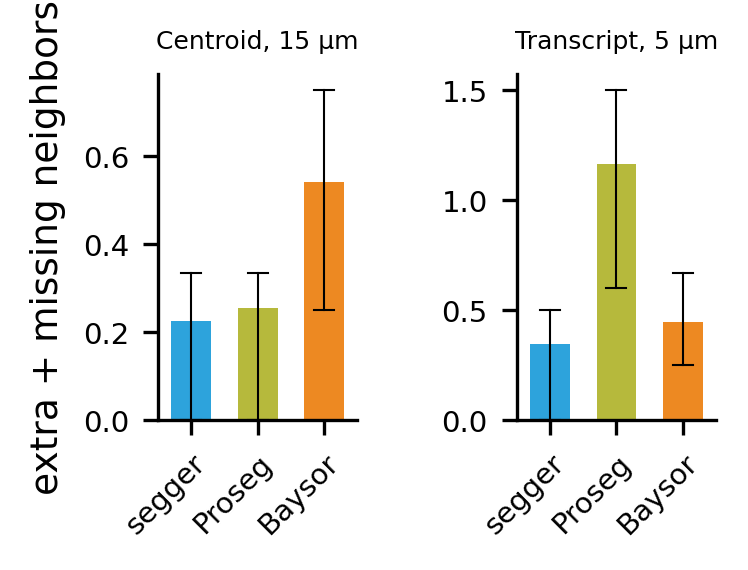

In [13]:
centroid_diff = centroid_neighbor_diffs(tx, SEGMENTATIONS, REFERENCE, all_mappings, radii=[20], **XY).with_columns(
    pl.col("segmentation").replace(NAMES), val=pl.col("symmetric_difference") / pl.col("b"),
)
transcript_diff = (
    pl.read_parquet(path_transcript_diffs)
    .filter(pl.col("radius") == 5.0)
    .with_columns(pl.col("segmentation").replace(NAMES), val=pl.col("symmetric_difference") / pl.col("b"))
)

fig, axes = plt.subplots(1, 2, figsize=(2.4, 1.5), gridspec_kw=dict(wspace=0.8))
barplot(centroid_diff.sample(100_000), axes[0], "val")
barplot(transcript_diff.sample(100_000), axes[1], "val")
axes[0].set_title("Centroid, 15 µm", fontsize=6)
axes[1].set_title("Transcript, 5 µm", fontsize=6)
axes[0].set_ylabel("extra + missing neighbors")
axes[1].set_ylabel("")
sg.pl.save_panel(fig, OUT_DIR / "panel_h-i")

## Software versions

In [14]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    display(sc.logging.print_header())

Package,Version
polars,1.40.0
geopandas,1.1.3
matplotlib,3.10.8
numpy,1.26.4
scanpy,1.11.5
seaborn,0.13.2
Component,Info
Python,"3.11.15 | packaged by conda-forge | (main, Mar 5 2026, 16:45:40) [GCC 14.3.0]"
OS,Linux-4.18.0-425.19.2.el8_7.x86_64-x86_64-with-glibc2.28
CPU,"16/64 logical CPU cores, x86_64"
